In [25]:
import pandas as pd

df = pd.read_csv('nigeria_fuel_prices.csv').dropna()
df

df.isnull().sum()

Year                   0
Crude_Oil_USD          0
Subsidy_NGN_Billion    0
FX_NGN_per_USD         0
Import_Duty_Pct        0
VAT_Pct                0
Price_NGN_per_Litre    0
dtype: int64


===== MODEL EVALUATION =====
Training MAE: 15.42
Testing MAE: 15.18
Training MSE: 408.89
Testing MSE: 303.82
Training R2: 1.0
Testing R2: 0.9

K-Fold CV scores (negated MAE): [  -71.58053954   -82.96158453    -9.9712556    -17.43942619
 -2765.38282861]

===== K-FOLD CROSS-VALIDATION =====
Fold 1 MAE: 71.58
Fold 2 MAE: 82.96
Fold 3 MAE: 9.97
Fold 4 MAE: 17.44
Fold 5 MAE: 2765.38
Average K-Fold MAE: 589.47
K-Fold MAE Standard Deviation: 1088.34

===== LEAVE-ONE-OUT CROSS-VALIDATION =====
Number of LOOCV iterations: 16
Average LOOCV MAE: 446.64
LOOCV MAE Standard Deviation: 1572.36

===== MODEL COMPARISON: MAE =====
      Evaluation        MAE
        Training  15.424049
         Testing  15.179353
       K-Fold CV 589.467127
Leave-One-Out CV 446.636585

Interpretation: MAE is the average absolute prediction error in NGN per litre.


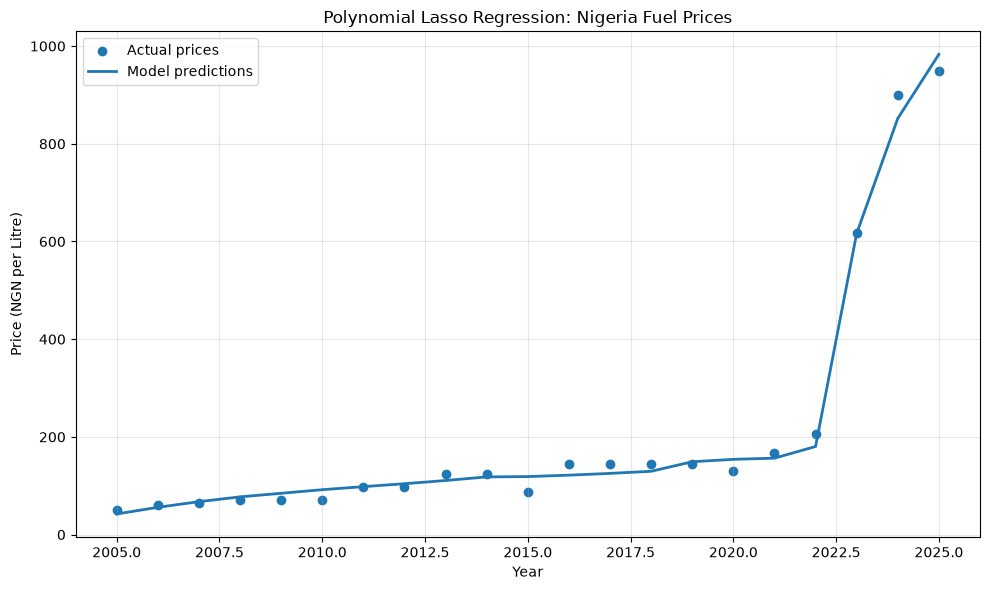

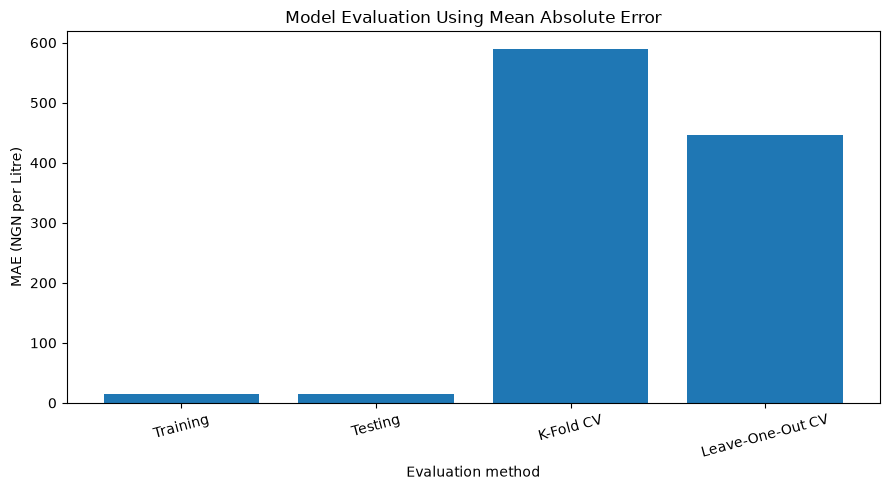


===== 2030 FUEL PRICE PREDICTION =====
Assumed feature values:
    Year  Crude_Oil_USD  Subsidy_NGN_Billion  FX_NGN_per_USD  Import_Duty_Pct  \
20    25             78                  0.0            1600                5   

    VAT_Pct  
20      7.5  

Predicted fuel price in 2030: 935.47 NGN per litre


In [26]:
# ============================================
# 1. IMPORT LIBRARIES
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Lasso
from sklearn.model_selection import (
    train_test_split,
    KFold,
    LeaveOneOut,
    cross_val_score
)
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from sklearn.preprocessing import (
    PolynomialFeatures,
    StandardScaler,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


# ============================================
# 3. PREPARE DATASET
# ============================================

target = "Price_NGN_per_Litre"

if target not in df.columns:
    raise ValueError(
        f"Target '{target}' not found. "
        f"Available columns: {df.columns.tolist()}"
    )

if "Year" not in df.columns:
    raise ValueError("Dataset must contain a Year column.")

df = df.copy()

# Convert target and Year to numeric
df[target] = pd.to_numeric(df[target], errors="coerce")
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")

# Remove records without target or Year
df = df.dropna(subset=[target, "Year"])
df = df.reset_index(drop=True)

if len(df) < 5:
    raise ValueError("At least 5 valid records are required.")

# Keep the original year for plotting and future prediction
original_years = df["Year"].copy()
base_year = original_years.min()

# Use all columns except the target as features
X = df.drop(columns=[target]).copy()
y = df[target].copy()

# Center Year to reduce numerical instability
X["Year"] = X["Year"] - base_year

# Remove completely empty features
X = X.dropna(axis=1, how="all")


# ============================================
# 4. IDENTIFY FEATURE TYPES
# ============================================

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()


# ============================================
# 5. CREATE PREPROCESSING PIPELINE
# ============================================

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Support both newer and older scikit-learn versions
import sklearn

sklearn_version = tuple(
    int(part) for part in sklearn.__version__.split(".")[:2]
)

if sklearn_version >= (1, 2):
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
else:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])

transformers = []

if numeric_features:
    transformers.append(
        ("num", numeric_transformer, numeric_features)
    )

if categorical_features:
    transformers.append(
        ("cat", categorical_transformer, categorical_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)


# ============================================
# 6. SPLIT DATASET
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

if len(X_train) < 2:
    raise ValueError(
        "Not enough training records for cross-validation."
    )


# ============================================
# 7. CREATE POLYNOMIAL LASSO REGRESSION MODEL
# ============================================

model = Pipeline([
    ("preprocessor", preprocessor),

    ("poly", PolynomialFeatures(
        degree=4,
        include_bias=False
    )),

    ("regression", Lasso(alpha=6 , max_iter=10000))
])

# PolynomialFeatures creates powers and interactions.
# Lasso regularization helps reduce overfitting and performs feature selection.

model.fit(X_train, y_train)


# ============================================
# 8. MODEL EVALUATION
# ============================================

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

train_mae = mean_absolute_error(y_train, y_pred_train)
test_mae = mean_absolute_error(y_test, y_pred_test)

train_mse = mean_squared_error(y_train, y_pred_train)
test_mse = mean_squared_error(y_test, y_pred_test)

print("\n===== MODEL EVALUATION =====")

print("Training MAE:", round(train_mae, 2))
print("Testing MAE:", round(test_mae, 2))

print("Training MSE:", round(train_mse, 2))
print("Testing MSE:", round(test_mse, 2))

print("Training R2:", round(r2_score(y_train, y_pred_train), 2))

if len(y_test) >= 2:
    print("Testing R2:", round(r2_score(y_test, y_pred_test), 2))
else:
    print("Testing R2: Undefined (fewer than 2 test records)")


# ============================================
# 9. DISPLAY MODEL COEFFICIENTS
# ============================================

regression = model.named_steps["regression"]
poly = model.named_steps["poly"]

feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

polynomial_names = poly.get_feature_names_out(feature_names)

coefficients_df = pd.DataFrame({
    "Feature": polynomial_names,
    "Coefficient": regression.coef_
})


# ============================================
# 10. K-FOLD CROSS-VALIDATION USING MAE
# ============================================

n_splits = min(5, len(X_train))

kfold = KFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=42
)

kfold_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=kfold,
    scoring="neg_mean_absolute_error",
    error_score="raise"
)

print("\nK-Fold CV scores (negated MAE):", kfold_scores)

# scikit-learn negates MAE because higher scores
# are preferred by its scoring convention.
kfold_mae = -kfold_scores

print("\n===== K-FOLD CROSS-VALIDATION =====")

for i, score in enumerate(kfold_mae, start=1):
    print(f"Fold {i} MAE: {score:.2f}")

print("Average K-Fold MAE:", round(kfold_mae.mean(), 2))
print("K-Fold MAE Standard Deviation:", round(kfold_mae.std(), 2))


# ============================================
# 11. LEAVE-ONE-OUT CROSS-VALIDATION USING MAE
# ============================================

loo = LeaveOneOut()

loo_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=loo,
    scoring="neg_mean_absolute_error",
    error_score="raise"
)

loo_mae = -loo_scores

print("\n===== LEAVE-ONE-OUT CROSS-VALIDATION =====")

print("Number of LOOCV iterations:", len(loo_mae))
print("Average LOOCV MAE:", round(loo_mae.mean(), 2))
print("LOOCV MAE Standard Deviation:", round(loo_mae.std(), 2))


# ============================================
# 12. COMPARE MODEL RESULTS
# ============================================

comparison = pd.DataFrame({
    "Evaluation": [
        "Training",
        "Testing",
        "K-Fold CV",
        "Leave-One-Out CV"
    ],
    "MAE": [
        train_mae,
        test_mae,
        kfold_mae.mean(),
        loo_mae.mean()
    ]
})

print("\n===== MODEL COMPARISON: MAE =====")
print(comparison.to_string(index=False))

print(
    "\nInterpretation: MAE is the average absolute "
    "prediction error in NGN per litre."
)


# ============================================
# 13. VISUALIZE ACTUAL VS PREDICTED PRICES
# ============================================

all_predictions = model.predict(X)

plot_df = pd.DataFrame({
    "Year": original_years.to_numpy(),
    "Actual": y.to_numpy(),
    "Predicted": all_predictions
})

plot_df = plot_df.sort_values("Year")

plt.figure(figsize=(10, 6))

plt.scatter(
    plot_df["Year"],
    plot_df["Actual"],
    label="Actual prices"
)

plt.plot(
    plot_df["Year"],
    plot_df["Predicted"],
    linewidth=2,
    label="Model predictions"
)

plt.title("Polynomial Lasso Regression: Nigeria Fuel Prices")
plt.xlabel("Year")
plt.ylabel("Price (NGN per Litre)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================
# 14. VISUALIZE MAE COMPARISON
# ============================================

plt.figure(figsize=(9, 5))

plt.bar(
    comparison["Evaluation"],
    comparison["MAE"]
)

plt.title("Model Evaluation Using Mean Absolute Error")
plt.xlabel("Evaluation method")
plt.ylabel("MAE (NGN per Litre)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# ============================================
# 15. PREDICT FUEL PRICE FOR 2030
# ============================================

latest_index = original_years.idxmax()

future_data = X.loc[[latest_index]].copy()

# Set the centered year to 2030
future_data.loc[:, "Year"] = 2030 - base_year

prediction_2030 = model.predict(future_data)

print("\n===== 2030 FUEL PRICE PREDICTION =====")

print("Assumed feature values:")
print(future_data)

print(
    "\nPredicted fuel price in 2030:",
    round(prediction_2030[0], 2),
    "NGN per litre"
)